# Data Loading and Setup



In [47]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("berkayyce/football-player-performance-and-personal-data")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'football-player-performance-and-personal-data' dataset.
Path to dataset files: /kaggle/input/football-player-performance-and-personal-data


In [48]:
import os
import pandas as pd
print(os.listdir(path))

['dataset.csv']


In [49]:
df=pd.read_csv(os.path.join(path,'dataset.csv'))
print(df.shape)

(4834, 38)


In [50]:
print(df.columns.tolist())

['Oyuncu', 'Yaş', 'Uyruk', 'Mevki', 'Sezon', 'Lig', 'Kategori', 'MP', 'DK', 'GLS', 'AST', 'ASR', 'TOS', 'SOT', 'BCM', 'KEYP', 'BCC', 'SDR', 'APS', 'APS%', 'ALB', 'LBA%', 'ACR', 'CA%', 'CLS', 'YC', 'RC', 'ELTG', 'DRP', 'TACK', 'INT', 'BLS', 'ADW', 'xG', 'xA', 'GI', 'XGI', 'Bonservis']


# Data Exploration and Cleaning ( Missingness, dtype issues, dedup, malformed row drop )

In [51]:
df[df['Oyuncu'] == 'Mateo Kovacic'][['Sezon', 'Lig', 'Bonservis']]

,Sezon,Lig,Bonservis
3126,24/25,Premier League,20.000.000
3127,23/24,Premier League,30.000.000
3128,22/23,Premier League,40.000.000
3129,21/22,Premier League,45.000.000
3130,20/21,Premier League,45.000.000
3131,19/20,Premier League,36.000.000
3132,18/19,Premier League,35.000.000
3133,17/18,LaLiga,30.000.000
3134,16/17,LaLiga,25.000.000
3135,15/16,LaLiga,20.000.000


In [52]:
df['Oyuncu'].nunique()

464

In [53]:
df_dedup = df.drop_duplicates(subset=['Oyuncu', 'Sezon'])
print(df_dedup.shape)

(3150, 38)


In [54]:
df_dedup

,Oyuncu,Yaş,Uyruk,Mevki,Sezon,Lig,Kategori,MP,DK,GLS,...,DRP,TACK,INT,BLS,ADW,xG,xA,GI,XGI,Bonservis
0,Aaron Cresswell,35,ENG,D,24/25,Premier League,Domestic leagues,18,847,0,...,2,11,8,1.0,7.0,0.23,1.90,0.0,2.14,500.000
1,Aaron Cresswell,34,ENG,D,23/24,Premier League,Domestic leagues,11,453,0,...,1,3,3,NaN,6.0,NaN,0.34,0.0,0.34,900.000
2,Aaron Cresswell,33,ENG,D,22/23,Premier League,Domestic leagues,28,2241,0,...,19,21,27,6.0,28.0,0.35,2.85,1.0,3.20,1.200.000
3,Aaron Cresswell,32,ENG,D,21/22,Premier League,Domestic leagues,31,2728,2,...,12,28,35,7.0,32.0,NaN,NaN,5.0,NaN,2.500.000
4,Aaron Cresswell,31,ENG,D,20/21,Premier League,Domestic leagues,36,3172,0,...,14,32,32,3.0,35.0,NaN,NaN,8.0,NaN,5.000.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4827,Yves Bissouma,24,MLI,OS,20/21,Premier League,Domestic leagues,36,3111,1,...,34,104,64,12.0,38.0,NaN,NaN,1.0,NaN,25.000.000
4828,Yves Bissouma,23,MLI,OS,19/20,Premier League,Domestic leagues,22,1265,1,...,23,49,21,2.0,17.0,NaN,NaN,1.0,NaN,9.500.000
4829,Yves Bissouma,22,MLI,OS,18/19,Premier League,Domestic leagues,28,1768,0,...,18,62,33,9.0,27.0,NaN,NaN,0.0,NaN,15.000.000
4830,Yves Bissouma,21,MLI,OS,17/18,Ligue 1,Domestic leagues,24,1555,2,...,20,67,30,15.0,22.0,NaN,NaN,3.0,NaN,8.000.000


In [55]:
df_dedup['Mevki'].value_counts()

,count
Mevki,
OS,1281
D,1246
F,623


In [56]:
df_dedup['Lig'].value_counts()

,count
Lig,
Premier League,1753
Championship,334
Ligue 1,139
Bundesliga,123
LaLiga,112
Serie A,108
Eredivisie,96
Liga Portugal Betclic,53
Brasileirão Betano,45


In [57]:
df_dedup[df_dedup['Mevki'] == 'OS'][['Oyuncu']]
# check the right position for players
# cause the labels are in Turkish

,Oyuncu
29,Abdoulaye Doucoure
30,Abdoulaye Doucoure
31,Abdoulaye Doucoure
32,Abdoulaye Doucoure
33,Abdoulaye Doucoure
...,...
4827,Yves Bissouma
4828,Yves Bissouma
4829,Yves Bissouma
4830,Yves Bissouma


In [58]:
epl=df_dedup[df_dedup['Lig']=='Premier League'].copy()
epl

,Oyuncu,Yaş,Uyruk,Mevki,Sezon,Lig,Kategori,MP,DK,GLS,...,DRP,TACK,INT,BLS,ADW,xG,xA,GI,XGI,Bonservis
0,Aaron Cresswell,35,ENG,D,24/25,Premier League,Domestic leagues,18,847,0,...,2,11,8,1.0,7.0,0.23,1.90,0.0,2.14,500.000
1,Aaron Cresswell,34,ENG,D,23/24,Premier League,Domestic leagues,11,453,0,...,1,3,3,NaN,6.0,NaN,0.34,0.0,0.34,900.000
2,Aaron Cresswell,33,ENG,D,22/23,Premier League,Domestic leagues,28,2241,0,...,19,21,27,6.0,28.0,0.35,2.85,1.0,3.20,1.200.000
3,Aaron Cresswell,32,ENG,D,21/22,Premier League,Domestic leagues,31,2728,2,...,12,28,35,7.0,32.0,NaN,NaN,5.0,NaN,2.500.000
4,Aaron Cresswell,31,ENG,D,20/21,Premier League,Domestic leagues,36,3172,0,...,14,32,32,3.0,35.0,NaN,NaN,8.0,NaN,5.000.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4825,Yves Bissouma,26,MLI,OS,22/23,Premier League,Domestic leagues,23,1029,0,...,5,16,12,2.0,6.0,0.17,0.37,0.0,0.54,18.000.000
4826,Yves Bissouma,25,MLI,OS,21/22,Premier League,Domestic leagues,26,2116,1,...,16,76,50,5.0,16.0,NaN,NaN,3.0,NaN,35.000.000
4827,Yves Bissouma,24,MLI,OS,20/21,Premier League,Domestic leagues,36,3111,1,...,34,104,64,12.0,38.0,NaN,NaN,1.0,NaN,25.000.000
4828,Yves Bissouma,23,MLI,OS,19/20,Premier League,Domestic leagues,22,1265,1,...,23,49,21,2.0,17.0,NaN,NaN,1.0,NaN,9.500.000


In [59]:
epl['Bonservis'].describe()

,Bonservis
count,1753
unique,98
top,25.000.000
freq,116


In [60]:
epl['Sezon'].value_counts().sort_index()

,count
Sezon,
15/16,37
16/17,52
17/18,73
18/19,98
19/20,135
19/21,1
20/21,159
21/22,193
22/23,267


In [61]:
epl.isnull().sum()

,0
Oyuncu,0
Yaş,0
Uyruk,0
Mevki,0
Sezon,0
Lig,0
Kategori,0
MP,0
DK,0
GLS,0


In [62]:
epl['Bonservis'].dtype

dtype('O')

In [63]:
epl[epl['Sezon'] == '19/21']
# season 19/21 typo, there are a lot of NaNs were dropped

,Oyuncu,Yaş,Uyruk,Mevki,Sezon,Lig,Kategori,MP,DK,GLS,...,DRP,TACK,INT,BLS,ADW,xG,xA,GI,XGI,Bonservis
4535,Valentino Livramento,17,ENG,D,19/21,Premier League,Domestic leagues,1,13,0,...,0,0,1,NaN,NaN,NaN,NaN,0.0,NaN,5.000.000


In [64]:
epl = epl[epl['Sezon'] != '19/21'].copy()
epl['Bonservis'] = epl['Bonservis'].str.replace('.', '', regex=False).astype(int)

In [65]:
epl.describe()

,Yaş,MP,DK,GLS,AST,ASR,TOS,SOT,BCM,KEYP,...,DRP,TACK,INT,BLS,ADW,xG,xA,GI,XGI,Bonservis
count,1752.000000,1752.000000,1752.000000,1752.000000,1752.000000,1744.000000,1659.000000,1659.000000,1752.000000,1752.000000,...,1752.000000,1752.000000,1752.000000,1659.000000,1674.000000,969.000000,1005.000000,1752.00000,1005.000000,1.752000e+03
mean,24.803082,24.127854,1698.743721,2.803082,2.086758,6.893085,26.033153,9.254973,2.497146,19.207192,...,15.517123,31.416667,17.876142,7.235684,30.010753,2.830330,1.748597,4.88984,4.477632,2.548710e+07
std,3.909825,10.541570,986.736932,4.121032,2.689406,0.246809,24.826019,10.550217,3.956068,19.766510,...,12.797761,24.538060,16.667202,7.431263,32.514467,3.717664,1.911325,6.02165,4.936006,2.412332e+07
min,15.000000,1.000000,1.000000,0.000000,0.000000,5.800000,1.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.00000,0.000000,2.000000e+05
25%,22.000000,16.000000,863.000000,0.000000,0.000000,6.740000,8.000000,2.000000,0.000000,5.000000,...,6.000000,13.000000,5.000000,2.000000,8.000000,0.520000,0.440000,1.00000,1.140000,1.000000e+07
50%,25.000000,27.000000,1743.500000,1.000000,1.000000,6.880000,18.000000,5.000000,1.000000,13.000000,...,13.000000,26.000000,13.000000,5.000000,19.000000,1.500000,1.090000,3.00000,2.740000,2.000000e+07
75%,27.000000,33.000000,2558.000000,4.000000,3.000000,7.040000,36.000000,13.000000,3.000000,27.000000,...,22.000000,46.000000,26.000000,10.000000,40.000000,3.510000,2.410000,7.00000,5.890000,3.500000e+07
max,38.000000,38.000000,3420.000000,36.000000,20.000000,8.010000,144.000000,67.000000,34.000000,137.000000,...,74.000000,144.000000,141.000000,47.000000,234.000000,29.320000,14.130000,47.00000,34.430000,3.000000e+08


In [66]:
epl['LBA%'].describe()

,LBA%
count,1655.000000
mean,50.664713
std,16.014072
min,9.100000
25%,39.200000
50%,50.000000
75%,60.950000
max,100.000000


In [67]:
epl['ELTG'].describe()

,ELTG
count,1752.000000
mean,0.218037
std,0.519582
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,4.000000


In [68]:
epl['ASR'].describe()

,ASR
count,1744.000000
mean,6.893085
std,0.246809
min,5.800000
25%,6.740000
50%,6.880000
75%,7.040000
max,8.010000


# Feature Selection and Train/Test Split
- The threshold of missingness is 20%, everything above it was dropped

In [69]:
from sklearn.model_selection import train_test_split

feature_cols = ['MP', 'DK', 'GLS', 'AST', 'TOS', 'SOT', 'BCM', 'KEYP', 'BCC', 'SDR',
                 'APS', 'APS%', 'CLS', 'YC', 'RC', 'DRP', 'TACK', 'INT', 'ADW', 'Yaş',
                 'ASR', 'ALB', 'LBA%', 'ACR', 'BLS', 'Mevki', 'Kategori']

X = epl[feature_cols]
y = epl['Bonservis']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.shape, X_test.shape)

(1401, 27) (351, 27)


# Preprocessing (imputation and encoding)

In [70]:
from sklearn.impute import SimpleImputer

impute_cols = ['ASR', 'ALB', 'LBA%', 'ACR', 'BLS', 'TOS', 'SOT', 'APS', 'APS%', 'ADW']

epl_imp = SimpleImputer(strategy='median')
X_train[impute_cols] = epl_imp.fit_transform(X_train[impute_cols])
X_test[impute_cols] = epl_imp.transform(X_test[impute_cols])

In [71]:
epl['Kategori'].value_counts()

,count
Kategori,
Domestic leagues,1752


In [72]:
X_train = X_train.drop(columns=['Kategori'])
X_test = X_test.drop(columns=['Kategori'])

In [73]:
print(feature_cols)

['MP', 'DK', 'GLS', 'AST', 'TOS', 'SOT', 'BCM', 'KEYP', 'BCC', 'SDR', 'APS', 'APS%', 'CLS', 'YC', 'RC', 'DRP', 'TACK', 'INT', 'ADW', 'Yaş', 'ASR', 'ALB', 'LBA%', 'ACR', 'BLS', 'Mevki', 'Kategori']


In [74]:
X_train.columns.tolist()

['MP',
 'DK',
 'GLS',
 'AST',
 'TOS',
 'SOT',
 'BCM',
 'KEYP',
 'BCC',
 'SDR',
 'APS',
 'APS%',
 'CLS',
 'YC',
 'RC',
 'DRP',
 'TACK',
 'INT',
 'ADW',
 'Yaş',
 'ASR',
 'ALB',
 'LBA%',
 'ACR',
 'BLS',
 'Mevki']

In [75]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')
X_train_encoded_array = encoder.fit_transform(X_train[['Mevki']])
X_test_encoded_array = encoder.transform(X_test[['Mevki']])

In [76]:
# Step 1: turn the encoded arrays into proper DataFrames with real column names
encoded_col_names = encoder.get_feature_names_out(['Mevki'])

X_train_encoded_df = pd.DataFrame(X_train_encoded_array, columns=encoded_col_names, index=X_train.index)
X_test_encoded_df = pd.DataFrame(X_test_encoded_array, columns=encoded_col_names, index=X_test.index)

# Step 2: drop the original text column from X_train/X_test
X_train = X_train.drop(columns=['Mevki'])
X_test = X_test.drop(columns=['Mevki'])

# Step 3: attach the new encoded columns
X_train = pd.concat([X_train, X_train_encoded_df], axis=1)
X_test = pd.concat([X_test, X_test_encoded_df], axis=1)

In [77]:
X_train.head()

,MP,DK,GLS,AST,TOS,SOT,BCM,KEYP,BCC,SDR,...,INT,ADW,Yaş,ASR,ALB,LBA%,ACR,BLS,Mevki_F,Mevki_OS
449,34,2213,4,5,25.0,10.0,1,32,6,28,...,16,4.0,28,6.89,59.0,57.8,13.0,10.0,0.0,1.0
3829,28,2133,9,5,57.0,22.0,8,43,11,37,...,11,5.0,21,7.30,19.0,67.9,36.0,16.0,0.0,1.0
2068,36,3101,1,1,10.0,6.0,0,5,1,5,...,84,97.0,24,6.81,82.0,33.2,4.0,0.0,0.0,0.0
3343,24,1343,1,1,16.0,6.0,0,17,1,28,...,34,39.0,21,6.87,41.0,48.8,0.0,7.0,0.0,1.0
4413,34,1500,1,4,17.0,8.0,0,26,5,26,...,13,14.0,32,6.97,41.0,58.6,5.0,3.0,0.0,1.0


In [78]:
X_train.isnull().sum().sum()

np.int64(0)

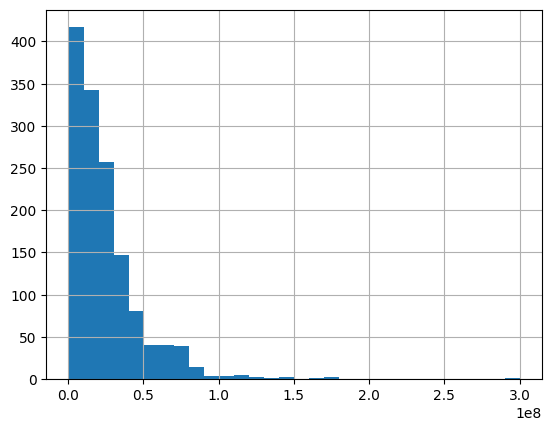

In [79]:
import matplotlib.pyplot as plt
y_train.hist(bins=30)
plt.show()

# Bseline model - Linear Regression

In [80]:
import numpy as np

y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)

In [81]:
from sklearn.linear_model import LinearRegression

model= LinearRegression()
model.fit(X_train, y_train_log)
predictions_log = model.predict(X_test)

In [82]:
from sklearn.metrics import root_mean_squared_error, r2_score
predictions_real = np.expm1(predictions_log)

rmse = root_mean_squared_error(y_test, predictions_real)
r2 = r2_score(y_test, predictions_real)

print(f"RMSE: {rmse}")
print(f"R²: {r2}")

RMSE: 18473803.45397737
R²: 0.27518388381681846


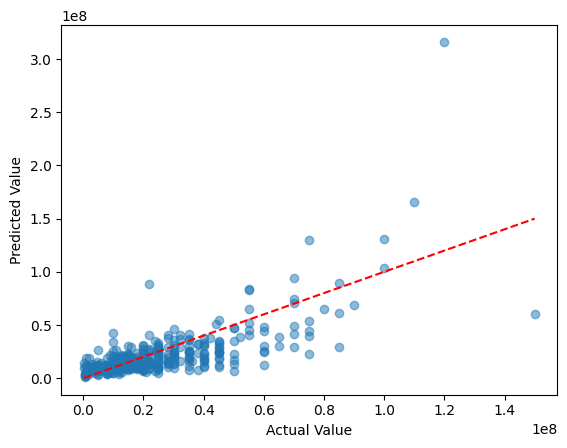

In [83]:
import matplotlib.pyplot as plt

plt.scatter(y_test, predictions_real, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual Value')
plt.ylabel('Predicted Value')
plt.show()

In [84]:
residuals = y_test - predictions_real
worst_idx = residuals.abs().idxmax()
epl.loc[worst_idx, ['Oyuncu', 'Sezon']], y_test.loc[worst_idx], predictions_real[y_test.index.get_loc(worst_idx)]

(Oyuncu    Rodri
 Sezon     23/24
 Name: 3986, dtype: object,
 np.int64(120000000),
 np.float64(316196225.442098))

# Imoroved Model - Random Forest

In [85]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train_log)

rf_predictions_log = rf_model.predict(X_test)
rf_predictions_real = np.expm1(rf_predictions_log)

rf_rmse = root_mean_squared_error(y_test, rf_predictions_real)
rf_r2 = r2_score(y_test, rf_predictions_real)

print(f"RF RMSE: {rf_rmse}")
print(f"RF R²: {rf_r2}")

RF RMSE: 14832863.556325391
RF R²: 0.532732896151008


In [86]:
importances = pd.Series(rf_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print(importances.head(10))

Yaş     0.193441
ASR     0.175617
DK      0.084671
MP      0.068166
APS     0.060961
SOT     0.053184
APS%    0.052052
TOS     0.044118
LBA%    0.037378
INT     0.023140
dtype: float64


# Model Comparison and Evaluation

In [87]:
comparison_df = pd.DataFrame([
    {"Model": "Linear Regression", "RMSE": rmse, "R²": r2},
    {"Model": "Random Forest", "RMSE": rf_rmse, "R²": rf_r2}
])

print(comparison_df.to_string(index=False))

            Model         RMSE       R²
Linear Regression 1.847380e+07 0.275184
    Random Forest 1.483286e+07 0.532733


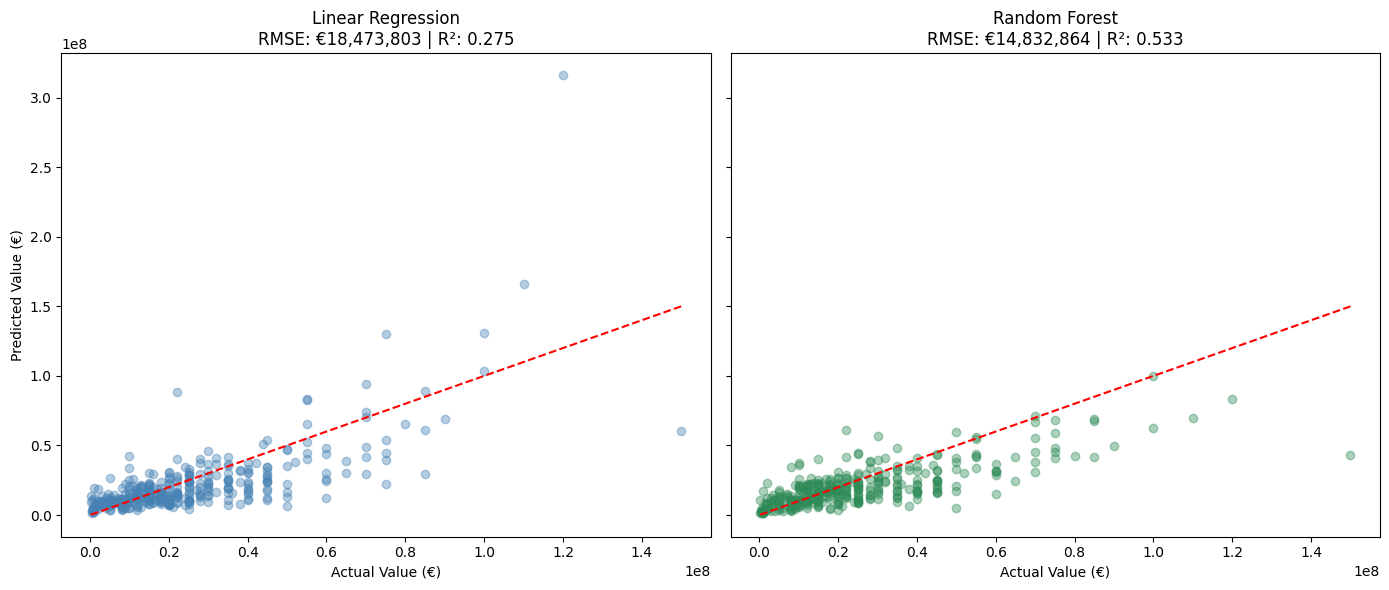

In [88]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)

# Linear Regression panel
axes[0].scatter(y_test, predictions_real, alpha=0.4, color='steelblue')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
axes[0].set_title(f'Linear Regression\nRMSE: €{rmse:,.0f} | R²: {r2:.3f}')
axes[0].set_xlabel('Actual Value (€)')
axes[0].set_ylabel('Predicted Value (€)')

# Random Forest panel
axes[1].scatter(y_test, rf_predictions_real, alpha=0.4, color='seagreen')
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
axes[1].set_title(f'Random Forest\nRMSE: €{rf_rmse:,.0f} | R²: {rf_r2:.3f}')
axes[1].set_xlabel('Actual Value (€)')

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

### Why Random Forest Outperformed Linear Regression

The increase in explained variance ($R^2$ increasing from **0.275** to **0.533**) and the ~20% reduction in prediction error (RMSE dropping from **€18.47M** to **€14.83M**) highlight fundamental structural differences in how each algorithm processes player data:

* **Capturing Non-Linear Age Dynamics:** Linear Regression enforces a constant slope across the entire feature space, assuming every additional year or goal adds or subtracts a fixed euro amount. In reality, player aging curves are non-linear: young talent can appreciate rapidly, whereas older veterans entering career decline lose market value at an accelerating rate. Random Forest's step-function splits naturally approximate these non-linear trajectories without requiring manual feature transformations.

* **Hypothesized Multi-Way Feature Interactions:** A primary structural advantage of tree-based ensembles is their capacity to partition data across nested branches, allowing them to capture potential multi-variable interactions automatically. In football valuation, feature effects likely depend heavily on context:
  * **Age $\times$ Position Hypothesis:** A 30-year-old central defender often retains significant market value due to positional longevity, whereas a 30-year-old winger relying on explosive pace may experience a much steeper valuation drop.
  * **Output $\times$ Position Hypothesis:** A goal scored by a central midfielder carries a different market premium compared to a goal scored by a striker.
  
  While Linear Regression treats these features independently unless interaction terms are explicitly constructed, Random Forest can hypothesize and isolate these conditional relationships through recursive partitioning.

* **Handling Skewed Distributions via Localized Bounding:** Football market values follow a right-skewed distribution dominated by high-value elite transfers. Because Linear Regression fits a single global hyperplane by minimizing overall squared residuals, extreme high-value data points exert significant leverage and pull the entire decision boundary upward. Random Forest manages this skew by isolating extreme values into specific leaf nodes, bounding their influence to localized regions of the feature space rather than distorting predictions across the entire dataset. However, this training-time robustness does not fully carry over to prediction accuracy — the model's own residuals (see evaluation plot above) still show substantially higher error for elite, high-value players, suggesting their valuations are driven by factors beyond what any of these features capture.


# Feature Importance ( Gini vs Permutation)

In [89]:
importances = pd.Series(rf_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print(importances.head(10))

Yaş     0.193441
ASR     0.175617
DK      0.084671
MP      0.068166
APS     0.060961
SOT     0.053184
APS%    0.052052
TOS     0.044118
LBA%    0.037378
INT     0.023140
dtype: float64


In [90]:
from sklearn.inspection import permutation_importance

perm_importance = permutation_importance(rf_model, X_test, y_test_log, n_repeats=10, random_state=42)
perm_df = pd.Series(perm_importance.importances_mean, index=X_train.columns).sort_values(ascending=False)
print(perm_df.head(10))

Yaş     0.327981
ASR     0.107606
MP      0.053885
APS     0.042669
DK      0.040371
APS%    0.033550
SOT     0.018892
SDR     0.012358
DRP     0.011312
LBA%    0.008971
dtype: float64


### Feature Importance: Gini vs. Permutation

To verify whether feature rankings reflected genuine predictive power or were artifacts of tree-based model bias, default **Gini Importance** (Mean Decrease in Impurity) was compared against **Permutation Importance** evaluated on the test set.

| Feature | Gini Importance | Permutation Importance |
| :--- | :---: | :---: |
| **Age (`Yaş`)** | 0.193 | **0.328** |
| **ASR (`Rating`)** | 0.176 | **0.108** |

#### Key Insights

* **Bias Correction Shift:** Under Permutation Importance, the gap between the top two features widened significantly—Age's importance rose from **0.193 to 0.328**, while ASR's relative contribution fell from **0.176 to 0.108**.
* **Methodological Reliability:** This shift reflects a known structural limitation of Gini Importance: it inherently overestimates continuous numerical variables with many unique values, as decision trees have more splitting opportunities on high-cardinality features. Permutation Importance directly measures the true degradation in $R^2$ when a feature's values are randomly shuffled, providing an unbiased metric.
* **Core Takeaway:** Both techniques confirm that **Age** and **ASR** are the two primary drivers of player market value. The fact that Age remains the dominant feature after controlling for impurity bias strengthens confidence that player age exerts a stronger influence on transfer valuation than any single on-pitch performance metric.

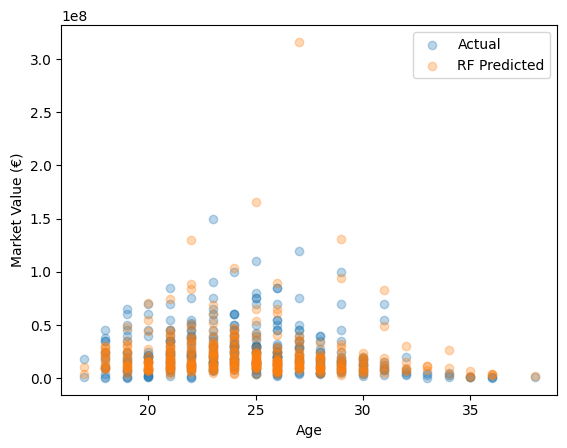

In [91]:
import matplotlib.pyplot as plt

plt.scatter(epl.loc[X_test.index, 'Yaş'], y_test, alpha=0.3, label='Actual')
plt.scatter(epl.loc[X_test.index, 'Yaş'], predictions_real, alpha=0.3, label='RF Predicted')
plt.xlabel('Age')
plt.ylabel('Market Value (€)')
plt.legend()
plt.show()